In [ ]:
!pip3 install torch_geometric

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 24.9 MB/s eta 0:00:00


In [ ]:
# ============================================================
# 1. MOUNT GOOGLE DRIVE
# ============================================================

from google.colab import drive

drive.mount('/content/drive')

data = '/content/drive/My Drive/GNN Project'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:

# ============================================================
# GNN-BASED DRUG TARGET IDENTIFICATION
# PREPROCESSING PIPELINE
# STRING PPI + DisGeNET
# ============================================================



# ============================================================
# 2. IMPORTS
# ============================================================

import pandas as pd
import numpy as np
import networkx as nx
import torch

from torch_geometric.data import Data
from torch_geometric.utils import to_undirected


# ============================================================
# 3. LOAD STRING PROTEIN INFORMATION
# ============================================================

print("============================================================")
print("1. Loading STRING protein information")
print("============================================================")

df_info = pd.read_csv(
    f"{data}/9606.protein.info.v12.0.txt",
    sep="\t"
)

# Remove the species prefix from STRING IDs
# Example: 9606.12345 -> 12345

df_info["clean_id"] = df_info["#string_protein_id"].apply(
    lambda x: str(x).split(".")[1]
    if "." in str(x)
    else str(x)
)

# Keep only the columns we need
df_info = df_info[
    ["clean_id", "preferred_name"]
].dropna()

# STRING protein ID -> gene name
protein_to_gene = dict(
    zip(
        df_info["clean_id"],
        df_info["preferred_name"]
    )
)

print(
    f"Mappage chargé : {len(protein_to_gene)} "
    f"protéines avec nom de gène connu."
)


# ============================================================
# 4. LOAD STRING PPI NETWORK
# ============================================================

print("\n============================================================")
print("2. Loading STRING PPI interactions")
print("============================================================")

df_links = pd.read_csv(
    f"{data}/9606.protein.links.v12.0.txt",
    sep=" "
)

# Clean STRING protein IDs

df_links["protein1"] = df_links["protein1"].apply(
    lambda x: str(x).split(".")[1]
    if "." in str(x)
    else str(x)
)

df_links["protein2"] = df_links["protein2"].apply(
    lambda x: str(x).split(".")[1]
    if "." in str(x)
    else str(x)
)


# ============================================================
# 5. FILTER HIGH-CONFIDENCE INTERACTIONS
# ============================================================

CONFIDENCE_THRESHOLD = 700

df_links = df_links[
    df_links["combined_score"] >= CONFIDENCE_THRESHOLD
]

print(
    f"Interactions de haute confiance chargées : "
    f"{len(df_links)}"
)


# ============================================================
# 6. BUILD NETWORKX PPI GRAPH
# ============================================================

print("\n============================================================")
print("3. Building NetworkX PPI graph")
print("============================================================")

G = nx.Graph()

edges_added = 0

for _, row in df_links.iterrows():

    protein1 = row["protein1"]
    protein2 = row["protein2"]

    # Only keep proteins that have a known gene name
    if (
        protein1 in protein_to_gene
        and protein2 in protein_to_gene
    ):

        G.add_edge(
            protein1,
            protein2
        )

        edges_added += 1


print(
    f"Arêtes ajoutées au graphe après correspondance "
    f"des noms : {edges_added}"
)


# ============================================================
# 7. KEEP LARGEST CONNECTED COMPONENT
# ============================================================

print("\n============================================================")
print("4. Selecting largest connected component")
print("============================================================")

largest_cc = max(
    nx.connected_components(G),
    key=len
)

G = G.subgraph(
    largest_cc
).copy()

print(
    f"Graphe principal construit : "
    f"{G.number_of_nodes()} nœuds, "
    f"{G.number_of_edges()} arêtes."
)


# ============================================================
# 8. CREATE NODE INDEX
# ============================================================

all_proteins = list(
    G.nodes()
)

protein_to_idx = {
    protein: idx
    for idx, protein in enumerate(all_proteins)
}

num_nodes = len(
    all_proteins
)


# ============================================================
# 9. LOAD DISGENET
# ============================================================

print("\n============================================================")
print("5. Loading DisGeNET disease associations")
print("============================================================")

df_disgenet = pd.read_csv(
    f"{data}/curated_gene_disease_associations.tsv",
    sep="\t"
)

disease_name = "Diabetes Mellitus"

disease_data = df_disgenet[
    df_disgenet["diseaseName"] == disease_name
]

disease_genes = set(
    disease_data["geneSymbol"]
    .astype(str)
    .str.upper()
)

print(
    f"Gènes associés à {disease_name} : "
    f"{len(disease_genes)}"
)


# ============================================================
# 10. CREATE DISEASE LABELS
# ============================================================

print("\n============================================================")
print("6. Creating disease labels")
print("============================================================")

labels = np.zeros(
    num_nodes,
    dtype=np.float32
)

for protein in all_proteins:

    gene_name = protein_to_gene.get(
        protein,
        ""
    ).upper()

    if gene_name in disease_genes:

        labels[
            protein_to_idx[protein]
        ] = 1


positive_count = int(
    labels.sum()
)

negative_count = (
    num_nodes - positive_count
)

print(
    f"Gènes malades présents dans le graphe : "
    f"{positive_count}"
)

print(
    f"Gènes non-malades dans le graphe : "
    f"{negative_count}"
)


# ============================================================
# 11. CALCULATE NODE FEATURES
# ============================================================

print("\n============================================================")
print("7. Calculating node features")
print("============================================================")

# ------------------------------------------------------------
# Feature 1: Degree
# ------------------------------------------------------------

print("Calculating degree...")

degrees = np.array(
    [
        G.degree(node)
        for node in all_proteins
    ],
    dtype=np.float32
)


# ------------------------------------------------------------
# Feature 2: Clustering coefficient
# ------------------------------------------------------------

print("Calculating clustering coefficient...")

clustering_dict = nx.clustering(G)

clustering = np.array(
    [
        clustering_dict[node]
        for node in all_proteins
    ],
    dtype=np.float32
)


# ------------------------------------------------------------
# Feature 3: PageRank
# ------------------------------------------------------------

print("Calculating PageRank...")

pagerank_dict = nx.pagerank(G)

pagerank = np.array(
    [
        pagerank_dict[node]
        for node in all_proteins
    ],
    dtype=np.float32
)


# ============================================================
# 12. COMBINE FEATURES
# ============================================================

features = np.column_stack(
    (
        degrees,
        clustering,
        pagerank
    )
).astype(np.float32)


print(
    f"Features before normalization: "
    f"{features.shape}"
)


# ============================================================
# 13. STANDARDIZE FEATURES
# ============================================================

features = (
    features - np.mean(
        features,
        axis=0
    )
) / (
    np.std(
        features,
        axis=0
    ) + 1e-8
)


print(
    "Features standardized."
)


# ============================================================
# 14. CONVERT NETWORKX EDGES TO PYTORCH GEOMETRIC
# ============================================================

print("\n============================================================")
print("8. Converting graph to PyTorch Geometric")
print("============================================================")

edge_index_list = [
    [
        protein_to_idx[u],
        protein_to_idx[v]
    ]
    for u, v in G.edges()
]


edge_index = torch.tensor(
    edge_index_list,
    dtype=torch.long
).t().contiguous()


# Make graph explicitly undirected
# Each edge will be represented in both directions

edge_index = to_undirected(
    edge_index
)


# ============================================================
# 15. CREATE PYTORCH TENSORS
# ============================================================

x = torch.tensor(
    features,
    dtype=torch.float
)

y = torch.tensor(
    labels,
    dtype=torch.float
)


# ============================================================
# 16. CREATE PYTORCH GEOMETRIC DATA OBJECT
# ============================================================

data_graph = Data(
    x=x,
    edge_index=edge_index,
    y=y
)


# ============================================================
# 17. SAVE PROCESSED DATASET
# ============================================================

print("\n============================================================")
print("9. Saving processed dataset")
print("============================================================")

processed_file = (
    f"{data}/diabetes_ppi_processed.pt"
)

torch.save(
    {
        "data": data_graph,
        "all_proteins": all_proteins,
        "protein_to_idx": protein_to_idx,
        "protein_to_gene": protein_to_gene
    },
    processed_file
)


# ============================================================
# 18. FINAL VERIFICATION
# ============================================================

print("\n============================================================")
print("PREPROCESSING COMPLETE")
print("============================================================")

print(
    f"Nodes             : {data_graph.num_nodes}"
)

print(
    f"Undirected edges  : {G.number_of_edges()}"
)

print(
    f"PyG edge entries  : {data_graph.edge_index.shape[1]}"
)

print(
    f"Features          : {data_graph.x.shape}"
)

print(
    f"Positive labels   : {int(data_graph.y.sum().item())}"
)

print(
    f"Negative labels   : "
    f"{data_graph.num_nodes - int(data_graph.y.sum().item())}"
)

print(
    f"\nSaved to:\n{processed_file}"
)

print("\nDataset is ready for GAT experiments.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
1. Loading STRING protein information
Mappage chargé : 19699 protéines avec nom de gène connu.

2. Loading STRING PPI interactions
Interactions de haute confiance chargées : 473860

3. Building NetworkX PPI graph
Arêtes ajoutées au graphe après correspondance des noms : 473860

4. Selecting largest connected component
Graphe principal construit : 15882 nœuds, 236712 arêtes.

5. Loading DisGeNET disease associations
Gènes associés à Diabetes Mellitus : 91

6. Creating disease labels
Gènes malades présents dans le graphe : 74
Gènes non-malades dans le graphe : 15808

7. Calculating node features
Calculating degree...
Calculating clustering coefficient...
Calculating PageRank...
Features before normalization: (15882, 3)
Features standardized.

8. Converting graph to PyTorch Geometric

9. Saving processed dataset

PREPROCESSING COMPLETE
Nodes             : 15882


In [ ]:
import numpy as np
import torch
import torch.nn.functional as F

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score

from torch_geometric.nn import GATConv


# ============================================================
# 1. Load processed dataset
# ============================================================

saved = torch.load(
    f"{data}/diabetes_ppi_processed.pt",
    weights_only=False
)

data_graph = saved["data"]

num_nodes = data_graph.num_nodes
num_edges = data_graph.edge_index.shape[1]
num_features = data_graph.x.shape[1]

positive_count = int(data_graph.y.sum().item())
negative_count = num_nodes - positive_count

print("Dataset")
print("-------")
print(f"Nodes       : {num_nodes}")
print(f"Edges       : {num_edges}")
print(f"Features    : {num_features}")
print(f"Positives   : {positive_count}")
print(f"Negatives   : {negative_count}")
print()


# ============================================================
# 2. Baseline GAT
# ============================================================

class ProfessionalGAT(torch.nn.Module):

    def __init__(
        self,
        num_features,
        hidden_channels,
        num_classes=1,
        heads=4,
        dropout=0.2
    ):
        super().__init__()

        self.conv1 = GATConv(
            num_features,
            hidden_channels // heads,
            heads=heads,
            concat=True
        )

        self.conv2 = GATConv(
            hidden_channels,
            hidden_channels // heads,
            heads=heads,
            concat=False
        )

        self.lin = torch.nn.Linear(
            hidden_channels // heads,
            num_classes
        )

        self.dropout = torch.nn.Dropout(p=dropout)

    def forward(self, x, edge_index):

        x = self.conv1(x, edge_index)
        x = F.elu(x)

        x = self.dropout(x)

        x = self.conv2(x, edge_index)
        x = F.elu(x)

        x = self.lin(x)

        return x


# ============================================================
# 3. Experiment configuration
# ============================================================

SEEDS = [42, 123, 456, 789, 2024]

HIDDEN_DIM = 128
HEADS = 4
DROPOUT = 0.2

LEARNING_RATE = 0.0001
WEIGHT_DECAY = 5e-4

MAX_EPOCHS = 100
PATIENCE = 100


# ============================================================
# 4. Run one seed
# ============================================================

def run_experiment(seed):

    print("=" * 70)
    print(f"SEED {seed}")
    print("=" * 70)

    # ----------------------------
    # Reproducibility
    # ----------------------------

    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)


    # ----------------------------
    # Stratified 60/20/20 split
    # ----------------------------

    indices = np.arange(num_nodes)

    train_idx, temp_idx = train_test_split(
        indices,
        test_size=0.40,
        stratify=data_graph.y.numpy(),
        random_state=seed
    )

    val_idx, test_idx = train_test_split(
        temp_idx,
        test_size=0.50,
        stratify=data_graph.y.numpy()[temp_idx],
        random_state=seed
    )


    train_idx = torch.tensor(
        train_idx,
        dtype=torch.long
    )

    val_idx = torch.tensor(
        val_idx,
        dtype=torch.long
    )

    test_idx = torch.tensor(
        test_idx,
        dtype=torch.long
    )


    # ----------------------------
    # Masks
    # ----------------------------

    train_mask = torch.zeros(
        num_nodes,
        dtype=torch.bool
    )

    val_mask = torch.zeros(
        num_nodes,
        dtype=torch.bool
    )

    test_mask = torch.zeros(
        num_nodes,
        dtype=torch.bool
    )

    train_mask[train_idx] = True
    val_mask[val_idx] = True
    test_mask[test_idx] = True


    # ----------------------------
    # Class imbalance
    # ----------------------------

    train_positive = (
        data_graph.y[train_mask] == 1
    ).sum().item()

    train_negative = (
        data_graph.y[train_mask] == 0
    ).sum().item()

    pos_weight_value = (
        train_negative / train_positive
    )

    pos_weight = torch.tensor(
        [pos_weight_value],
        dtype=torch.float
    )


    # ----------------------------
    # Model
    # ----------------------------

    torch.manual_seed(seed)

    model = ProfessionalGAT(
        num_features=num_features,
        hidden_channels=HIDDEN_DIM,
        heads=HEADS,
        dropout=DROPOUT
    )


    # ----------------------------
    # Loss
    # ----------------------------

    criterion = torch.nn.BCEWithLogitsLoss(
        pos_weight=pos_weight
    )


    # ----------------------------
    # Optimizer
    # ----------------------------

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )


    # ----------------------------
    # Training
    # ----------------------------

    best_val_auc = 0.0
    best_epoch = 0

    best_model_state = None

    epochs_without_improvement = 0

    for epoch in range(1, MAX_EPOCHS + 1):

        # ========================
        # TRAIN
        # ========================

        model.train()

        optimizer.zero_grad()

        logits = model(
            data_graph.x,
            data_graph.edge_index
        ).squeeze()

        loss = criterion(
            logits[train_mask],
            data_graph.y[train_mask]
        )

        loss.backward()

        optimizer.step()


        # ========================
        # VALIDATION
        # ========================

        model.eval()

        with torch.no_grad():

            val_logits = model(
                data_graph.x,
                data_graph.edge_index
            ).squeeze()

            val_probabilities = torch.sigmoid(
                val_logits[val_mask]
            ).cpu().numpy()

            val_labels = (
                data_graph.y[val_mask]
                .cpu()
                .numpy()
            )

            val_auc = roc_auc_score(
                val_labels,
                val_probabilities
            )


        # ========================
        # Save best model
        # ========================

        if val_auc > best_val_auc:

            best_val_auc = val_auc

            best_epoch = epoch

            best_model_state = {
                key: value.cpu().clone()
                for key, value in model.state_dict().items()
            }

            epochs_without_improvement = 0

        else:

            epochs_without_improvement += 1


        print(
            f"Epoch {epoch:03d} | "
            f"Loss: {loss.item():.4f} | "
            f"Val ROC-AUC: {val_auc:.4f}"
        )


        if epochs_without_improvement >= PATIENCE:

            print(
                f"\nEarly stopping at epoch {epoch}"
            )

            break


    # ========================================================
    # 5. Restore best model
    # ========================================================

    model.load_state_dict(best_model_state)

    model.eval()


    # ========================================================
    # 6. Test
    # ========================================================

    with torch.no_grad():

        test_logits = model(
            data_graph.x,
            data_graph.edge_index
        ).squeeze()

        test_probabilities = torch.sigmoid(
            test_logits[test_mask]
        ).cpu().numpy()

        test_labels = (
            data_graph.y[test_mask]
            .cpu()
            .numpy()
        )


    # ========================================================
    # 7. ROC-AUC
    # ========================================================

    test_roc_auc = roc_auc_score(
        test_labels,
        test_probabilities
    )


    # ========================================================
    # 8. PR-AUC
    # ========================================================

    test_pr_auc = average_precision_score(
        test_labels,
        test_probabilities
    )


    # ========================================================
    # 9. Results
    # ========================================================

    print()
    print(f"Best validation ROC-AUC : {best_val_auc:.4f}")
    print(f"Best epoch              : {best_epoch}")
    print(f"Test ROC-AUC            : {test_roc_auc:.4f}")
    print(f"Test PR-AUC             : {test_pr_auc:.4f}")
    print()

    return {
        "seed": seed,
        "best_val_auc": best_val_auc,
        "best_epoch": best_epoch,
        "test_roc_auc": test_roc_auc,
        "test_pr_auc": test_pr_auc
    }


# ============================================================
# 10. Run all five seeds
# ============================================================

results = []

for seed in SEEDS:

    result = run_experiment(seed)

    results.append(result)


# ============================================================
# 11. Summary
# ============================================================

print("\n")
print("=" * 70)
print("FINAL BASELINE RESULTS")
print("=" * 70)

print(
    f"{'Seed':<10}"
    f"{'Val ROC-AUC':<15}"
    f"{'Test ROC-AUC':<15}"
    f"{'Test PR-AUC':<15}"
)

print("-" * 70)

for r in results:

    print(
        f"{r['seed']:<10}"
        f"{r['best_val_auc']:<15.4f}"
        f"{r['test_roc_auc']:<15.4f}"
        f"{r['test_pr_auc']:<15.4f}"
    )


# ============================================================
# 12. Aggregate statistics
# ============================================================

mean_val_auc = np.mean([
    r["best_val_auc"]
    for r in results
])

mean_test_roc_auc = np.mean([
    r["test_roc_auc"]
    for r in results
])

std_test_roc_auc = np.std([
    r["test_roc_auc"]
    for r in results
])

mean_test_pr_auc = np.mean([
    r["test_pr_auc"]
    for r in results
])

std_test_pr_auc = np.std([
    r["test_pr_auc"]
    for r in results
])


print()
print("=" * 70)
print("AGGREGATE RESULTS")
print("=" * 70)

print(
    f"Mean validation ROC-AUC : "
    f"{mean_val_auc:.4f}"
)

print(
    f"Mean test ROC-AUC       : "
    f"{mean_test_roc_auc:.4f}"
)

print(
    f"Std test ROC-AUC        : "
    f"{std_test_roc_auc:.4f}"
)

print(
    f"Mean test PR-AUC        : "
    f"{mean_test_pr_auc:.4f}"
)

print(
    f"Std test PR-AUC         : "
    f"{std_test_pr_auc:.4f}"
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset
-------
Nodes       : 15882
Edges       : 473424
Features    : 3
Positives   : 74
Negatives   : 15808

SEED 42
Epoch 001 | Loss: 1.3760 | Val ROC-AUC: 0.7212
Epoch 002 | Loss: 1.3736 | Val ROC-AUC: 0.7249
Epoch 003 | Loss: 1.3714 | Val ROC-AUC: 0.7274
Epoch 004 | Loss: 1.3719 | Val ROC-AUC: 0.7300
Epoch 005 | Loss: 1.3709 | Val ROC-AUC: 0.7323
Epoch 006 | Loss: 1.3720 | Val ROC-AUC: 0.7343
Epoch 007 | Loss: 1.3696 | Val ROC-AUC: 0.7358
Epoch 008 | Loss: 1.3723 | Val ROC-AUC: 0.7369
Epoch 009 | Loss: 1.3708 | Val ROC-AUC: 0.7378
Epoch 010 | Loss: 1.3696 | Val ROC-AUC: 0.7386
Epoch 011 | Loss: 1.3697 | Val ROC-AUC: 0.7396
Epoch 012 | Loss: 1.3672 | Val ROC-AUC: 0.7402
Epoch 013 | Loss: 1.3681 | Val ROC-AUC: 0.7410
Epoch 014 | Loss: 1.3662 | Val ROC-AUC: 0.7415
Epoch 015 | Loss: 1.3676 | Val ROC-AUC: 0.7425
Epoch 016 | Loss: 1.3673 | Val ROC-AUC: 0.7434


In [ ]:
# ============================================================
# SGAT - Sparse Graph Attention Network
# Based on Ye & Ji, "Sparse Graph Attention Networks", TKDE 2021
# Adapted to PyTorch Geometric and the diabetes PPI graph
# ============================================================

import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.nn import MessagePassing
from torch_geometric.utils import softmax

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score


# ============================================================
# 1. Reproducibility
# ============================================================

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)


# ============================================================
# 2. Load processed dataset
# ============================================================

DATA_PATH = "/content/drive/My Drive/GNN Project/diabetes_ppi_processed.pt"

data_dict = torch.load(DATA_PATH, weights_only=False)

data = data_dict["data"]

print("Nodes       :", data.num_nodes)
print("Edges       :", data.edge_index.shape[1])
print("Features    :", data.x.shape)
print("Positives   :", int(data.y.sum()))
print("Negatives   :", int((data.y == 0).sum()))


# ============================================================
# 3. Device
# ============================================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

data = data.to(device)


# ============================================================
# 4. Stratified 60/20/20 split
# ============================================================

def create_split(y, seed=42):

    y_cpu = y.detach().cpu().numpy()
    indices = np.arange(len(y_cpu))

    train_idx, temp_idx = train_test_split(
        indices,
        test_size=0.40,
        stratify=y_cpu,
        random_state=seed
    )

    temp_y = y_cpu[temp_idx]

    val_idx, test_idx = train_test_split(
        temp_idx,
        test_size=0.50,
        stratify=temp_y,
        random_state=seed
    )

    train_mask = torch.zeros(len(y_cpu), dtype=torch.bool)
    val_mask = torch.zeros(len(y_cpu), dtype=torch.bool)
    test_mask = torch.zeros(len(y_cpu), dtype=torch.bool)

    train_mask[train_idx] = True
    val_mask[val_idx] = True
    test_mask[test_idx] = True

    return (
        train_mask.to(device),
        val_mask.to(device),
        test_mask.to(device)
    )


train_mask, val_mask, test_mask = create_split(data.y, seed=42)

print("\nSplit:")
print("Train:", int(train_mask.sum()))
print("Val  :", int(val_mask.sum()))
print("Test :", int(test_mask.sum()))

print("\nPositive nodes:")
print("Train:", int(data.y[train_mask].sum()))
print("Val  :", int(data.y[val_mask].sum()))
print("Test :", int(data.y[test_mask].sum()))


# ============================================================
# 5. Sparse Attention Layer
#
# IMPORTANT:
# SGAT learns ONE edge-level mask which is shared across
# GNN layers.
#
# We use a hard-concrete style stochastic gate to approximate
# L0 regularization while keeping the model differentiable.
# ============================================================

class SparseEdgeAttention(MessagePassing):

    def __init__(
        self,
        in_channels,
        out_channels,
        dropout=0.2,
        heads=1
    ):
        super().__init__(
            aggr="add",
            node_dim=0
        )

        self.in_channels = in_channels
        self.out_channels = out_channels
        self.dropout = dropout
        self.heads = heads

        # Node transformation
        self.lin = nn.Linear(
            in_channels,
            out_channels,
            bias=False
        )

        # Attention parameters
        self.att_src = nn.Parameter(
            torch.empty(out_channels)
        )

        self.att_dst = nn.Parameter(
            torch.empty(out_channels)
        )

        # Edge mask generator
        #
        # One scalar per edge.
        # These parameters are SHARED between layers.
        self.edge_score = nn.Parameter(
            torch.empty(1)
        )

        self.reset_parameters()


    def reset_parameters(self):

        nn.init.xavier_uniform_(self.lin.weight)

        nn.init.xavier_uniform_(
            self.att_src.view(1, -1)
        )

        nn.init.xavier_uniform_(
            self.att_dst.view(1, -1)
        )

        nn.init.constant_(
            self.edge_score,
            0.0
        )


    def forward(
        self,
        x,
        edge_index,
        edge_gate
    ):

        # Transform node features
        x = self.lin(x)

        row, col = edge_index

        # Standard GAT-style attention
        alpha_src = (x * self.att_src).sum(dim=-1)

        alpha_dst = (x * self.att_dst).sum(dim=-1)

        alpha = alpha_src[row] + alpha_dst[col]

        alpha = F.leaky_relu(
            alpha,
            negative_slope=0.2
        )

        alpha = softmax(
            alpha,
            row
        )

        alpha = F.dropout(
            alpha,
            p=self.dropout,
            training=self.training
        )

        # ----------------------------------------------------
        # Sparse edge mask
        # ----------------------------------------------------
        #
        # The gate is applied directly to the attention.
        #
        alpha = alpha * edge_gate

        return self.propagate(
            edge_index,
            x=x,
            alpha=alpha
        )


    def message(self, x_j, alpha):

        return alpha.unsqueeze(-1) * x_j


# ============================================================
# 6. SGAT Model
#
# One edge mask is learned and reused by BOTH layers.
# ============================================================

class SGAT(nn.Module):

    def __init__(
        self,
        num_features,
        hidden_channels=128,
        dropout=0.2
    ):

        super().__init__()

        self.dropout = dropout

        self.conv1 = SparseEdgeAttention(
            num_features,
            hidden_channels,
            dropout=dropout
        )

        self.conv2 = SparseEdgeAttention(
            hidden_channels,
            hidden_channels,
            dropout=dropout
        )

        self.classifier = nn.Linear(
            hidden_channels,
            1
        )

        # ----------------------------------------------------
        # ONE learnable score per graph edge.
        #
        # This is the sparse mask shared by both layers.
        # ----------------------------------------------------

        self.edge_logits = None


    def initialize_edge_mask(self, num_edges, device):

        self.edge_logits = nn.Parameter(
            torch.zeros(
                num_edges,
                device=device
            )
        )

        nn.init.normal_(
            self.edge_logits,
            mean=0.0,
            std=0.01
        )

        self.register_parameter(
            "edge_gate_logits",
            self.edge_logits
        )


    def sample_edge_gate(self):

        """
        Hard-concrete style stochastic gate.

        During training:
            stochastic gate

        During evaluation:
            deterministic sigmoid gate
        """

        logits = self.edge_gate_logits

        if self.training:

            uniform = torch.rand_like(logits)

            uniform = uniform.clamp(
                1e-6,
                1 - 1e-6
            )

            logistic_noise = (
                torch.log(uniform)
                - torch.log(1 - uniform)
            )

            gate = torch.sigmoid(
                logits + logistic_noise
            )

        else:

            gate = torch.sigmoid(
                logits
            )

        return gate


    def forward(
        self,
        x,
        edge_index
    ):

        edge_gate = self.sample_edge_gate()

        x = self.conv1(
            x,
            edge_index,
            edge_gate
        )

        x = F.elu(x)

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        # SAME edge gate used again
        x = self.conv2(
            x,
            edge_index,
            edge_gate
        )

        x = F.elu(x)

        logits = self.classifier(x)

        return logits.squeeze(-1), edge_gate


# ============================================================
# 7. L0 regularization
# ============================================================

def l0_regularization(model):

    """
    Approximate expected number of active edges.

    This is the sparsity term of the SGAT objective.
    """

    gate_probability = torch.sigmoid(
        model.edge_gate_logits
    )

    return gate_probability.sum()


# ============================================================
# 8. Create model
# ============================================================

set_seed(42)

model = SGAT(
    num_features=data.num_features,
    hidden_channels=128,
    dropout=0.2
).to(device)

model.initialize_edge_mask(
    num_edges=data.edge_index.shape[1],
    device=device
)

print(model)
print("\nNumber of edge gates:", model.edge_gate_logits.numel())


# ============================================================
# 9. Positive class weight
# ============================================================

num_positive = int(data.y[train_mask].sum())
num_negative = int((data.y[train_mask] == 0).sum())

pos_weight = (
    num_negative / num_positive
)

print("\nPositive weight:", pos_weight)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        pos_weight,
        device=device
    )
)


# ============================================================
# 10. Optimizer
# ============================================================

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4,
    weight_decay=5e-4
)


# ============================================================
# 11. SGAT hyperparameters
# ============================================================

MAX_EPOCHS = 100

PATIENCE = 30

# L0 regularization coefficient.
#
# Start small.
# We will inspect the resulting sparsity before tuning it.
L0_LAMBDA = 1e-6


# ============================================================
# 12. Training
# ============================================================

best_val_auc = -float("inf")

best_state = None

patience_counter = 0

print("\n" + "=" * 70)
print("STARTING SGAT TRAINING")
print("=" * 70)

for epoch in range(1, MAX_EPOCHS + 1):

    model.train()

    optimizer.zero_grad()

    logits, edge_gate = model(
        data.x,
        data.edge_index
    )

    # Classification loss
    classification_loss = criterion(
        logits[train_mask],
        data.y[train_mask].float()
    )

    # L0 sparsity loss
    sparsity_loss = (
        L0_LAMBDA *
        l0_regularization(model)
    )

    # Total objective
    loss = (
        classification_loss +
        sparsity_loss
    )

    loss.backward()

    optimizer.step()


    # ========================================================
    # Validation
    # ========================================================

    model.eval()

    with torch.no_grad():

        val_logits, val_gate = model(
            data.x,
            data.edge_index
        )

        val_probs = torch.sigmoid(
            val_logits[val_mask]
        ).detach().cpu().numpy()

        val_labels = (
            data.y[val_mask]
            .detach()
            .cpu()
            .numpy()
        )

        val_auc = roc_auc_score(
            val_labels,
            val_probs
        )

        val_pr = average_precision_score(
            val_labels,
            val_probs
        )


    # ========================================================
    # Calculate current sparsity
    # ========================================================

    with torch.no_grad():

        deterministic_gate = torch.sigmoid(
            model.edge_gate_logits
        )

        active_edges = (
            deterministic_gate > 0.5
        ).sum().item()

        total_edges = (
            deterministic_gate.numel()
        )

        sparsity = (
            1 -
            active_edges / total_edges
        )


    # ========================================================
    # Save best model
    # ========================================================

    if val_auc > best_val_auc:

        best_val_auc = val_auc

        best_state = {
            k: v.detach().cpu().clone()
            for k, v in model.state_dict().items()
        }

        patience_counter = 0

    else:

        patience_counter += 1


    # ========================================================
    # Logging
    # ========================================================

    if epoch == 1 or epoch % 5 == 0:

        print(
            f"Epoch {epoch:03d} | "
            f"Loss {loss.item():.5f} | "
            f"Cls {classification_loss.item():.5f} | "
            f"L0 {sparsity_loss.item():.5f} | "
            f"Val ROC-AUC {val_auc:.4f} | "
            f"Val PR-AUC {val_pr:.4f} | "
            f"Sparsity {sparsity:.2%}"
        )


    if patience_counter >= PATIENCE:

        print(
            f"\nEarly stopping at epoch {epoch}"
        )

        break


# ============================================================
# 13. Restore best checkpoint
# ============================================================

model.load_state_dict(best_state)

print("\nBest validation ROC-AUC:", best_val_auc)


# ============================================================
# 14. Final test evaluation
# ============================================================

model.eval()

with torch.no_grad():

    test_logits, test_gate = model(
        data.x,
        data.edge_index
    )

    test_probs = torch.sigmoid(
        test_logits[test_mask]
    ).cpu().numpy()

    test_labels = (
        data.y[test_mask]
        .cpu()
        .numpy()
    )

test_auc = roc_auc_score(
    test_labels,
    test_probs
)

test_pr_auc = average_precision_score(
    test_labels,
    test_probs
)


# ============================================================
# 15. Final sparsity
# ============================================================

with torch.no_grad():

    final_gate = torch.sigmoid(
        model.edge_gate_logits
    )

    # Threshold only for reporting the learned sparse graph
    retained_mask = (
        final_gate > 0.5
    )

    retained_edges = int(
        retained_mask.sum().item()
    )

    total_edges = int(
        final_gate.numel()
    )

    removed_edges = (
        total_edges -
        retained_edges
    )

    final_sparsity = (
        removed_edges /
        total_edges
    )


print("\n" + "=" * 70)
print("SGAT FINAL RESULTS")
print("=" * 70)

print(f"Test ROC-AUC       : {test_auc:.4f}")
print(f"Test PR-AUC        : {test_pr_auc:.4f}")

print(f"\nOriginal edge entries : {total_edges:,}")
print(f"Retained edge entries: {retained_edges:,}")
print(f"Removed edge entries  : {removed_edges:,}")

print(
    f"Sparsity              : "
    f"{final_sparsity:.2%}"
)

print("=" * 70)

Nodes       : 15882
Edges       : 473424
Features    : torch.Size([15882, 3])
Positives   : 74
Negatives   : 15808
Device: cpu

Split:
Train: 9529
Val  : 3176
Test : 3177

Positive nodes:
Train: 44
Val  : 15
Test : 15
SGAT(
  (conv1): SparseEdgeAttention(3, 128)
  (conv2): SparseEdgeAttention(128, 128)
  (classifier): Linear(in_features=128, out_features=1, bias=True)
)

Number of edge gates: 473424

Positive weight: 215.5681818181818

STARTING SGAT TRAINING
Epoch 001 | Loss 1.61658 | Cls 1.37987 | L0 0.23671 | Val ROC-AUC 0.5375 | Val PR-AUC 0.0057 | Sparsity 50.32%
Epoch 005 | Loss 1.61388 | Cls 1.37717 | L0 0.23671 | Val ROC-AUC 0.6923 | Val PR-AUC 0.0108 | Sparsity 51.87%
Epoch 010 | Loss 1.61152 | Cls 1.37481 | L0 0.23671 | Val ROC-AUC 0.7231 | Val PR-AUC 0.0129 | Sparsity 53.73%
Epoch 015 | Loss 1.60867 | Cls 1.37196 | L0 0.23670 | Val ROC-AUC 0.7320 | Val PR-AUC 0.0140 | Sparsity 55.43%
Epoch 020 | Loss 1.60641 | Cls 1.36970 | L0 0.23670 | Val ROC-AUC 0.7392 | Val PR-AUC 0.0148 

In [ ]:
# ============================================================
# SAVE SGAT CHECKPOINT + EXPERIMENT RESULTS
# ============================================================

import os
import json
import torch

PROJECT_DIR = "/content/drive/My Drive/GNN Project"

MODEL_PATH = os.path.join(
    PROJECT_DIR,
    "diabetes_sgat_best.pt"
)

RESULTS_PATH = os.path.join(
    PROJECT_DIR,
    "diabetes_sgat_results.json"
)


# ------------------------------------------------------------
# 1. Save complete model checkpoint
# ------------------------------------------------------------

checkpoint = {
    # Model
    "model_state_dict": model.state_dict(),

    # Dataset/model configuration
    "num_features": data.num_features,
    "hidden_channels": 128,
    "dropout": 0.2,

    # Training configuration
    "learning_rate": 1e-4,
    "weight_decay": 5e-4,
    "l0_lambda": L0_LAMBDA,
    "max_epochs": MAX_EPOCHS,
    "patience": PATIENCE,

    # Split
    "split_seed": 42,

    # Metrics
    "best_val_roc_auc": float(best_val_auc),
    "test_roc_auc": float(test_auc),
    "test_pr_auc": float(test_pr_auc),

    # Sparsity
    "total_edge_entries": int(total_edges),
    "retained_edge_entries": int(retained_edges),
    "removed_edge_entries": int(removed_edges),
    "sparsity": float(final_sparsity),

    # Dataset information
    "num_nodes": int(data.num_nodes),
    "num_edges": int(data.edge_index.shape[1]),
    "num_positive": int(data.y.sum()),
    "num_negative": int((data.y == 0).sum()),

    # Learned mask
    "edge_gate_logits": model.edge_gate_logits.detach().cpu()
}

torch.save(
    checkpoint,
    MODEL_PATH
)


# ------------------------------------------------------------
# 2. Save results separately as JSON
# ------------------------------------------------------------

results = {
    "experiment": "SGAT",
    "dataset": "Diabetes Mellitus PPI",

    "num_nodes": int(data.num_nodes),
    "edge_entries": int(data.edge_index.shape[1]),
    "features": int(data.num_features),

    "positive_nodes": int(data.y.sum()),
    "negative_nodes": int((data.y == 0).sum()),

    "split": {
        "train": int(train_mask.sum()),
        "validation": int(val_mask.sum()),
        "test": int(test_mask.sum()),
        "seed": 42
    },

    "model": {
        "architecture": "Sparse Graph Attention Network",
        "hidden_channels": 128,
        "dropout": 0.2,
        "learning_rate": 1e-4,
        "weight_decay": 5e-4
    },

    "performance": {
        "best_validation_roc_auc": float(best_val_auc),
        "test_roc_auc": float(test_auc),
        "test_pr_auc": float(test_pr_auc)
    },

    "sparsity": {
        "original_edges": int(total_edges),
        "retained_edges": int(retained_edges),
        "removed_edges": int(removed_edges),
        "sparsity_ratio": float(final_sparsity)
    }
}

with open(RESULTS_PATH, "w") as f:
    json.dump(results, f, indent=4)


print("=" * 70)
print("SGAT MODEL SAVED")
print("=" * 70)

print("Model:")
print(MODEL_PATH)

print("\nResults:")
print(RESULTS_PATH)

print("\nTest ROC-AUC :", test_auc)
print("Test PR-AUC  :", test_pr_auc)
print("Sparsity     :", final_sparsity)

print("=" * 70)

SGAT MODEL SAVED
Model:
/content/drive/My Drive/GNN Project/diabetes_sgat_best.pt

Results:
/content/drive/My Drive/GNN Project/diabetes_sgat_results.json

Test ROC-AUC : 0.6817415138098251
Test PR-AUC  : 0.016739508187587876
Sparsity     : 0.7148264557774848


In [ ]:
# ============================================================
# RELOAD PROCESSED DATASET
# ============================================================

import torch

DATA_PATH = "/content/drive/My Drive/GNN Project/diabetes_ppi_processed.pt"

loaded = torch.load(
    DATA_PATH,
    weights_only=False
)

# The actual PyG Data object is stored under "data"
data = loaded["data"]

print("=" * 50)
print("Dataset reloaded successfully")
print("=" * 50)

print("Nodes        :", data.num_nodes)
print("Edges        :", data.edge_index.shape[1])
print("Features     :", data.x.shape)
print("Positive     :", int(data.y.sum()))
print("Negative     :", int((data.y == 0).sum()))

Dataset reloaded successfully
Nodes        : 15882
Edges        : 473424
Features     : torch.Size([15882, 3])
Positive     : 74
Negative     : 15808


In [ ]:
# ============================================================
# STEP 1 — INSPECT SGAT ARCHITECTURE
# ============================================================

import torch

print("SGAT architecture:")
print(model)

print("\n" + "="*60)
print("PARAMETER SHAPES")
print("="*60)

for name, param in model.named_parameters():
    print(f"{name:40s} {tuple(param.shape)}")

print("\n" + "="*60)
print("TOTAL PARAMETERS")
print("="*60)

total_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {total_params:,}")

SGAT architecture:
SGAT(
  (conv1): SparseEdgeAttention(3, 128)
  (conv2): SparseEdgeAttention(128, 128)
  (classifier): Linear(in_features=128, out_features=1, bias=True)
)

PARAMETER SHAPES
edge_logits                              (473424,)
conv1.att_src                            (128,)
conv1.att_dst                            (128,)
conv1.edge_score                         (1,)
conv1.lin.weight                         (128, 3)
conv2.att_src                            (128,)
conv2.att_dst                            (128,)
conv2.edge_score                         (1,)
conv2.lin.weight                         (128, 128)
classifier.weight                        (1, 128)
classifier.bias                          (1,)

TOTAL PARAMETERS
Total parameters: 490,835


In [ ]:
# ============================================================
# STEP 2 — LOAD BEST SGAT CHECKPOINT
# ============================================================

import torch
import os

MODEL_PATH = "/content/drive/My Drive/GNN Project/diabetes_sgat_best.pt"

checkpoint = torch.load(
    MODEL_PATH,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("\nCheckpoint keys:")
    for key in checkpoint.keys():
        print(" -", key)

Checkpoint type: <class 'dict'>

Checkpoint keys:
 - model_state_dict
 - num_features
 - hidden_channels
 - dropout
 - learning_rate
 - weight_decay
 - l0_lambda
 - max_epochs
 - patience
 - split_seed
 - best_val_roc_auc
 - test_roc_auc
 - test_pr_auc
 - total_edge_entries
 - retained_edge_entries
 - removed_edge_entries
 - sparsity
 - num_nodes
 - num_edges
 - num_positive
 - num_negative
 - edge_gate_logits


In [ ]:
# ============================================================
# STEP 3 — LOAD SGAT INCLUDING LEARNED EDGE GATES
# ============================================================

import torch

DEVICE = torch.device("cpu")

MODEL_PATH = "/content/drive/My Drive/GNN Project/diabetes_sgat_best.pt"

checkpoint = torch.load(
    MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)

# ------------------------------------------------------------
# Recreate SGAT architecture
# ------------------------------------------------------------

model_prune = SGAT(
    num_features=data.num_features,
    hidden_channels=128,
    dropout=0.2
).to(DEVICE)

# ------------------------------------------------------------
# Load normal model parameters
# ------------------------------------------------------------

model_prune.load_state_dict(
    checkpoint["model_state_dict"],
    strict=False
)

# ------------------------------------------------------------
# Restore learned edge gate
# ------------------------------------------------------------

if "edge_gate_logits" in checkpoint:

    model_prune.edge_gate_logits = torch.nn.Parameter(
        checkpoint["edge_gate_logits"]
        .detach()
        .clone()
        .to(DEVICE)
    )

    print("✓ edge_gate_logits restored")

elif "edge_logits" in checkpoint:

    model_prune.edge_gate_logits = torch.nn.Parameter(
        checkpoint["edge_logits"]
        .detach()
        .clone()
        .to(DEVICE)
    )

    print("✓ edge_logits restored as edge_gate_logits")

else:

    raise RuntimeError(
        "No edge gate tensor found in checkpoint."
    )

model_prune.eval()

print()
print("=" * 60)
print("SGAT MODEL READY FOR PRUNING")
print("=" * 60)

print(model_prune)

print()
print("edge_gate_logits shape:",
      tuple(model_prune.edge_gate_logits.shape))

print("Expected edge count:",
      data.edge_index.shape[1])

print()
print("Best validation ROC-AUC:",
      checkpoint["best_val_roc_auc"])

print("Original test ROC-AUC:",
      checkpoint["test_roc_auc"])

print("Original test PR-AUC:",
      checkpoint["test_pr_auc"])

print("Original sparsity:",
      checkpoint["sparsity"])

✓ edge_gate_logits restored

SGAT MODEL READY FOR PRUNING
SGAT(
  (conv1): SparseEdgeAttention(3, 128)
  (conv2): SparseEdgeAttention(128, 128)
  (classifier): Linear(in_features=128, out_features=1, bias=True)
)

edge_gate_logits shape: (473424,)
Expected edge count: 473424

Best validation ROC-AUC: 0.7699884002952653
Original test ROC-AUC: 0.6817415138098251
Original test PR-AUC: 0.016739508187587876
Original sparsity: 0.7148264557774848


In [ ]:
# ============================================================
# STEP 4 — RECREATE EXACT SGAT SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

y_np = data.y.cpu().numpy()

indices = np.arange(data.num_nodes)

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.40,
    stratify=y_np,
    random_state=42
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    stratify=y_np[temp_idx],
    random_state=42
)

train_mask_prune = torch.zeros(data.num_nodes, dtype=torch.bool)
val_mask_prune   = torch.zeros(data.num_nodes, dtype=torch.bool)
test_mask_prune  = torch.zeros(data.num_nodes, dtype=torch.bool)

train_mask_prune[train_idx] = True
val_mask_prune[val_idx] = True
test_mask_prune[test_idx] = True

print("=" * 60)
print("SPLIT CHECK")
print("=" * 60)

print("Train:", int(train_mask_prune.sum()))
print("Val  :", int(val_mask_prune.sum()))
print("Test :", int(test_mask_prune.sum()))

print()

print("Train positives:",
      int(data.y[train_mask_prune].sum()))

print("Val positives:",
      int(data.y[val_mask_prune].sum()))

print("Test positives:",
      int(data.y[test_mask_prune].sum()))

SPLIT CHECK
Train: 9529
Val  : 3176
Test : 3177

Train positives: 44
Val positives: 15
Test positives: 15


In [ ]:
# ============================================================
# STEP 5 — CALCULATE HIDDEN NEURON IMPORTANCE
# ============================================================

with torch.no_grad():

    # Importance from the final classifier
    classifier_importance = (
        model_prune.classifier.weight
        .abs()
        .squeeze(0)
    )

    # Importance from the incoming weights to conv2
    conv2_importance = (
        model_prune.conv2.lin.weight
        .abs()
        .sum(dim=0)
    )

    # Normalize both components
    classifier_norm = (
        classifier_importance /
        (classifier_importance.max() + 1e-12)
    )

    conv2_norm = (
        conv2_importance /
        (conv2_importance.max() + 1e-12)
    )

    # Combined importance
    neuron_importance = (
        0.5 * classifier_norm +
        0.5 * conv2_norm
    )

# Rank neurons from most important → least important
ranked_neurons = torch.argsort(
    neuron_importance,
    descending=True
)

print("=" * 60)
print("NEURON IMPORTANCE")
print("=" * 60)

print("Number of hidden neurons:",
      len(neuron_importance))

print("\nTop 10 neurons:")

for rank, neuron_id in enumerate(ranked_neurons[:10], start=1):

    print(
        f"{rank:2d}. "
        f"Neuron {neuron_id.item():3d} "
        f"importance = "
        f"{neuron_importance[neuron_id].item():.6f}"
    )

NEURON IMPORTANCE
Number of hidden neurons: 128

Top 10 neurons:
 1. Neuron 100 importance = 0.970203
 2. Neuron  71 importance = 0.923510
 3. Neuron  25 importance = 0.917891
 4. Neuron  38 importance = 0.912077
 5. Neuron 123 importance = 0.902441
 6. Neuron  75 importance = 0.893695
 7. Neuron   0 importance = 0.890286
 8. Neuron  24 importance = 0.883458
 9. Neuron  58 importance = 0.883039
10. Neuron  80 importance = 0.882607


In [ ]:
# ============================================================
# STEP 6 — STRUCTURED NEURON PRUNING
# ============================================================

import copy
import torch
import numpy as np
from sklearn.metrics import roc_auc_score, average_precision_score


# ============================================================
# 1. PRUNING FUNCTION
# ============================================================

def prune_sgat_neurons(model, keep_indices):

    """
    Structurally retain selected hidden neurons.

    Hidden dimension:
        128 → N

    Modified layers:
        conv1
        conv2
        classifier
    """

    if isinstance(keep_indices, torch.Tensor):
        keep_indices = keep_indices.detach().clone().long()
    else:
        keep_indices = torch.tensor(
            keep_indices,
            dtype=torch.long
        )

    new_hidden = len(keep_indices)

    # Copy trained model
    pruned = copy.deepcopy(model)

    # ========================================================
    # CONV1
    # ========================================================

    old_weight = pruned.conv1.lin.weight.data.clone()

    pruned.conv1.lin = torch.nn.Linear(
        3,
        new_hidden,
        bias=False
    )

    pruned.conv1.lin.weight.data.copy_(
        old_weight[keep_indices]
    )

    # Attention vectors
    old_att_src = pruned.conv1.att_src.data.clone()
    old_att_dst = pruned.conv1.att_dst.data.clone()

    pruned.conv1.att_src = torch.nn.Parameter(
        old_att_src[keep_indices]
    )

    pruned.conv1.att_dst = torch.nn.Parameter(
        old_att_dst[keep_indices]
    )

    # ========================================================
    # CONV2
    # ========================================================

    old_weight = pruned.conv2.lin.weight.data.clone()

    pruned.conv2.lin = torch.nn.Linear(
        new_hidden,
        new_hidden,
        bias=False
    )

    pruned.conv2.lin.weight.data.copy_(
        old_weight[
            keep_indices
        ][:, keep_indices]
    )

    old_att_src = pruned.conv2.att_src.data.clone()
    old_att_dst = pruned.conv2.att_dst.data.clone()

    pruned.conv2.att_src = torch.nn.Parameter(
        old_att_src[keep_indices]
    )

    pruned.conv2.att_dst = torch.nn.Parameter(
        old_att_dst[keep_indices]
    )

    # ========================================================
    # CLASSIFIER
    # ========================================================

    old_classifier_weight = (
        pruned.classifier.weight.data.clone()
    )

    old_classifier_bias = (
        pruned.classifier.bias.data.clone()
    )

    pruned.classifier = torch.nn.Linear(
        new_hidden,
        1
    )

    pruned.classifier.weight.data.copy_(
        old_classifier_weight[:, keep_indices]
    )

    pruned.classifier.bias.data.copy_(
        old_classifier_bias
    )

    return pruned


# ============================================================
# 2. EVALUATION FUNCTION
# ============================================================

def evaluate_model(model, mask):

    model.eval()

    with torch.no_grad():

        # Your SGAT returns:
        #   element 0 = node predictions
        #   element 1 = edge gates

        output = model(
            data.x,
            data.edge_index
        )

        logits = output[0]

        probabilities = torch.sigmoid(logits)

    y_true = data.y[mask].cpu().numpy()
    y_score = probabilities[mask].cpu().numpy()

    roc = roc_auc_score(
        y_true,
        y_score
    )

    pr = average_precision_score(
        y_true,
        y_score
    )

    return roc, pr


# ============================================================
# 3. PRUNING LEVELS
# ============================================================

pruning_levels = [
    128,
    96,
    64,
    48,
    32,
    24,
    16,
    12,
    8,
    4
]


results_pruning = []


print("=" * 80)
print("STRUCTURED NEURON PRUNING")
print("=" * 80)


# ============================================================
# 4. RUN EXPERIMENT
# ============================================================

for n_keep in pruning_levels:

    # Most important neurons
    selected = ranked_neurons[:n_keep]

    # Create pruned model
    pruned_model = prune_sgat_neurons(
        model_prune,
        selected
    )

    # Validation only
    val_roc, val_pr = evaluate_model(
        pruned_model,
        val_mask_prune
    )

    results_pruning.append({
        "neurons": int(n_keep),
        "val_roc_auc": float(val_roc),
        "val_pr_auc": float(val_pr)
    })

    print(
        f"Neurons: {n_keep:3d} | "
        f"Val ROC-AUC: {val_roc:.4f} | "
        f"Val PR-AUC: {val_pr:.4f}"
    )


print("=" * 80)
print("PRUNING EXPERIMENT COMPLETE")
print("=" * 80)

STRUCTURED NEURON PRUNING
Neurons: 128 | Val ROC-AUC: 0.7700 | Val PR-AUC: 0.0233
Neurons:  96 | Val ROC-AUC: 0.7136 | Val PR-AUC: 0.0176
Neurons:  64 | Val ROC-AUC: 0.7208 | Val PR-AUC: 0.0144
Neurons:  48 | Val ROC-AUC: 0.7568 | Val PR-AUC: 0.0165
Neurons:  32 | Val ROC-AUC: 0.7377 | Val PR-AUC: 0.0151
Neurons:  24 | Val ROC-AUC: 0.6870 | Val PR-AUC: 0.0116
Neurons:  16 | Val ROC-AUC: 0.5725 | Val PR-AUC: 0.0074
Neurons:  12 | Val ROC-AUC: 0.3298 | Val PR-AUC: 0.0037
Neurons:   8 | Val ROC-AUC: 0.2894 | Val PR-AUC: 0.0035
Neurons:   4 | Val ROC-AUC: 0.6671 | Val PR-AUC: 0.0110
PRUNING EXPERIMENT COMPLETE


In [ ]:
# ============================================================
# STEP 7 — FINE-GRAINED BACKBONE SEARCH
# ============================================================

fine_pruning_levels = [
    64,
    56,
    48,
    40,
    36,
    32,
    28,
    24,
    20,
    16
]

fine_results = []

print("=" * 80)
print("FINE-GRAINED BACKBONE SEARCH")
print("=" * 80)

for n_keep in fine_pruning_levels:

    selected = ranked_neurons[:n_keep]

    pruned_model = prune_sgat_neurons(
        model_prune,
        selected
    )

    val_roc, val_pr = evaluate_model(
        pruned_model,
        val_mask_prune
    )

    fine_results.append({
        "neurons": int(n_keep),
        "val_roc_auc": float(val_roc),
        "val_pr_auc": float(val_pr)
    })

    print(
        f"Neurons: {n_keep:3d} | "
        f"Val ROC-AUC: {val_roc:.4f} | "
        f"Val PR-AUC: {val_pr:.4f}"
    )

print("=" * 80)
print("FINE SEARCH COMPLETE")
print("=" * 80)

FINE-GRAINED BACKBONE SEARCH
Neurons:  64 | Val ROC-AUC: 0.7208 | Val PR-AUC: 0.0144
Neurons:  56 | Val ROC-AUC: 0.7493 | Val PR-AUC: 0.0161
Neurons:  48 | Val ROC-AUC: 0.7568 | Val PR-AUC: 0.0165
Neurons:  40 | Val ROC-AUC: 0.7357 | Val PR-AUC: 0.0154
Neurons:  36 | Val ROC-AUC: 0.7246 | Val PR-AUC: 0.0140
Neurons:  32 | Val ROC-AUC: 0.7377 | Val PR-AUC: 0.0151
Neurons:  28 | Val ROC-AUC: 0.7454 | Val PR-AUC: 0.0152
Neurons:  24 | Val ROC-AUC: 0.6870 | Val PR-AUC: 0.0116
Neurons:  20 | Val ROC-AUC: 0.6616 | Val PR-AUC: 0.0108
Neurons:  16 | Val ROC-AUC: 0.5725 | Val PR-AUC: 0.0074
FINE SEARCH COMPLETE


FINAL NEURON DESTRUCTION CURVE
Baseline validation ROC-AUC : 0.7700
95% threshold                : 0.7315

 Neurons |  Val ROC-AUC |  Val PR-AUC |   Removed |   >=95%
------------------------------------------------------------------------------------------
     128 |       0.7700 |      0.0233 |      0.0% |     YES
      96 |       0.7136 |      0.0176 |     25.0% |      NO
      64 |       0.7208 |      0.0144 |     50.0% |      NO
      56 |       0.7493 |      0.0161 |     56.2% |     YES
      48 |       0.7568 |      0.0165 |     62.5% |     YES
      40 |       0.7357 |      0.0154 |     68.8% |     YES
      36 |       0.7246 |      0.0140 |     71.9% |      NO
      32 |       0.7377 |      0.0151 |     75.0% |     YES
      28 |       0.7454 |      0.0152 |     78.1% |     YES
      24 |       0.6870 |      0.0116 |     81.2% |      NO
      20 |       0.6616 |      0.0108 |     84.4% |      NO
      16 |       0.5725 |      0.0074 |     87.5% |      NO
      12 |       0.329

,neurons,val_roc_auc,val_pr_auc,removed_percent,relative_val_roc
0,128,0.769988,0.023292,0.000,100.000000
1,96,0.713645,0.017568,25.000,92.682626
2,64,0.720806,0.014396,50.000,93.612534
3,56,0.749341,0.016098,56.250,97.318469
4,48,0.756796,0.016450,62.500,98.286724
5,40,0.735674,0.015373,68.750,95.543565
6,36,0.724560,0.014021,71.875,94.100085
7,32,0.737699,0.015055,75.000,95.806513
8,28,0.745418,0.015222,78.125,96.809006
9,24,0.686998,0.011628,81.250,89.221836


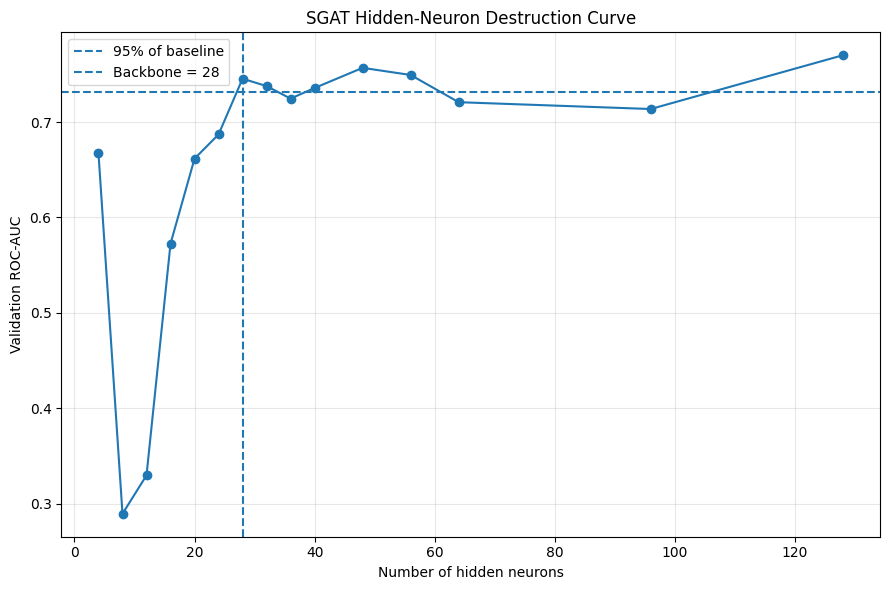

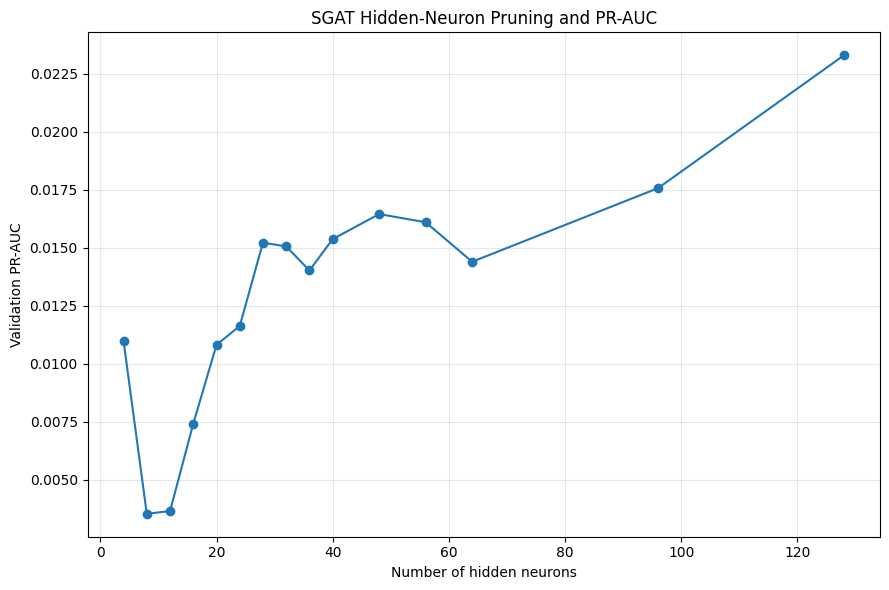


FINAL RESULTS SAVED
/content/drive/My Drive/GNN Project/diabetes_sgat_neuron_pruning_final.json


In [ ]:
# ============================================================
# FINAL PRUNING ANALYSIS
# ============================================================

import os
import json
import matplotlib.pyplot as plt
import pandas as pd


# ============================================================
# 1. COMBINE ALL PRUNING RESULTS
# ============================================================

all_pruning_results = results_pruning.copy()

# Replace/add fine-grained results
existing_levels = {
    r["neurons"] for r in all_pruning_results
}

for r in fine_results:

    if r["neurons"] not in existing_levels:
        all_pruning_results.append(r)

# Sort from largest → smallest
all_pruning_results = sorted(
    all_pruning_results,
    key=lambda x: x["neurons"],
    reverse=True
)


# ============================================================
# 2. BASELINE VALIDATION PERFORMANCE
# ============================================================

baseline_val_roc = next(
    r["val_roc_auc"]
    for r in all_pruning_results
    if r["neurons"] == 128
)

baseline_val_pr = next(
    r["val_pr_auc"]
    for r in all_pruning_results
    if r["neurons"] == 128
)

threshold_95 = 0.95 * baseline_val_roc


# ============================================================
# 3. FIND SMALLEST VALIDATION BACKBONE
# ============================================================

valid_backbones = [
    r
    for r in all_pruning_results
    if r["val_roc_auc"] >= threshold_95
]

backbone_result = min(
    valid_backbones,
    key=lambda x: x["neurons"]
)

backbone = backbone_result["neurons"]


# ============================================================
# 4. PRINT DESTRUCTION TABLE
# ============================================================

print("=" * 90)
print("FINAL NEURON DESTRUCTION CURVE")
print("=" * 90)

print(
    f"Baseline validation ROC-AUC : "
    f"{baseline_val_roc:.4f}"
)

print(
    f"95% threshold                : "
    f"{threshold_95:.4f}"
)

print()

print(
    f"{'Neurons':>8} | "
    f"{'Val ROC-AUC':>12} | "
    f"{'Val PR-AUC':>11} | "
    f"{'Removed':>9} | "
    f"{'>=95%':>7}"
)

print("-" * 90)


for r in all_pruning_results:

    n = r["neurons"]

    removed_pct = (
        1 - n / 128
    ) * 100

    passes = (
        r["val_roc_auc"] >= threshold_95
    )

    print(
        f"{n:8d} | "
        f"{r['val_roc_auc']:12.4f} | "
        f"{r['val_pr_auc']:11.4f} | "
        f"{removed_pct:8.1f}% | "
        f"{'YES' if passes else 'NO':>7}"
    )


print()
print("=" * 90)
print("VALIDATION-SELECTED BACKBONE")
print("=" * 90)

print(
    f"Backbone neurons : {backbone}"
)

print(
    f"Validation ROC-AUC : "
    f"{backbone_result['val_roc_auc']:.4f}"
)

print(
    f"Validation PR-AUC : "
    f"{backbone_result['val_pr_auc']:.4f}"
)

print(
    f"Neuron reduction : "
    f"{(1 - backbone / 128) * 100:.2f}%"
)


# ============================================================
# 5. FINAL TEST EVALUATION
# ============================================================

selected_backbone = ranked_neurons[:backbone]

final_pruned_model = prune_sgat_neurons(
    model_prune,
    selected_backbone
)

final_test_roc, final_test_pr = evaluate_model(
    final_pruned_model,
    test_mask_prune/0/home
)


# ============================================================
# 6. ORIGINAL SGAT TEST PERFORMANCE
# ============================================================

original_test_roc, original_test_pr = evaluate_model(
    model_prune,
    test_mask_prune
)


print()
print("=" * 90)
print("FINAL TEST EVALUATION")
print("=" * 90)

print(
    f"Original SGAT ({128} neurons)")
print(
    f"  Test ROC-AUC : {original_test_roc:.4f}"
)
print(
    f"  Test PR-AUC  : {original_test_pr:.4f}"
)

print()

print(
    f"Backbone SGAT ({backbone} neurons)"
)
print(
    f"  Test ROC-AUC : {final_test_roc:.4f}"
)
print(
    f"  Test PR-AUC  : {final_test_pr:.4f}"
)

print()

print(
    f"Neuron reduction : "
    f"{(1 - backbone / 128) * 100:.2f}%"
)

print("=" * 90)


# ============================================================
# 7. CREATE DATAFRAME
# ============================================================

df_pruning = pd.DataFrame(
    all_pruning_results
)

df_pruning["removed_percent"] = (
    1 -
    df_pruning["neurons"] / 128
) * 100

df_pruning["relative_val_roc"] = (
    df_pruning["val_roc_auc"] /
    baseline_val_roc
) * 100


print()
print("Final pruning dataframe:")
display(df_pruning)


# ============================================================
# 8. DESTRUCTION CURVE — ROC-AUC
# ============================================================

plot_df = df_pruning.sort_values(
    "neurons"
)

plt.figure(figsize=(9, 6))

plt.plot(
    plot_df["neurons"],
    plot_df["val_roc_auc"],
    marker="o"
)

plt.axhline(
    threshold_95,
    linestyle="--",
    label="95% of baseline"
)

plt.axvline(
    backbone,
    linestyle="--",
    label=f"Backbone = {backbone}"
)

plt.xlabel(
    "Number of hidden neurons"
)

plt.ylabel(
    "Validation ROC-AUC"
)

plt.title(
    "SGAT Hidden-Neuron Destruction Curve"
)

plt.legend()

plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.show()


# ============================================================
# 9. DESTRUCTION CURVE — PR-AUC
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    plot_df["neurons"],
    plot_df["val_pr_auc"],
    marker="o"
)

plt.xlabel(
    "Number of hidden neurons"
)

plt.ylabel(
    "Validation PR-AUC"
)

plt.title(
    "SGAT Hidden-Neuron Pruning and PR-AUC"
)

plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.show()


# ============================================================
# 10. SAVE FINAL PRUNING RESULTS
# ============================================================

PRUNING_RESULTS_PATH = os.path.join(
    PROJECT_DIR,
    "diabetes_sgat_neuron_pruning_final.json"
)

final_results = {

    "experiment":
        "SGAT structured neuron pruning",

    "original_hidden_neurons":
        128,

    "backbone_neurons":
        int(backbone),

    "neuron_reduction_percent":
        float(
            (1 - backbone / 128) * 100
        ),

    "selection_criterion":
        "Smallest tested hidden dimension retaining at least 95% of unpruned validation ROC-AUC",

    "baseline_validation_roc_auc":
        float(baseline_val_roc),

    "backbone_validation_roc_auc":
        float(
            backbone_result["val_roc_auc"]
        ),

    "backbone_validation_pr_auc":
        float(
            backbone_result["val_pr_auc"]
        ),

    "original_test_roc_auc":
        float(original_test_roc),

    "original_test_pr_auc":
        float(original_test_pr),

    "backbone_test_roc_auc":
        float(final_test_roc),

    "backbone_test_pr_auc":
        float(final_test_pr),

    "results":
        all_pruning_results
}


with open(
    PRUNING_RESULTS_PATH,
    "w"
) as f:

    json.dump(
        final_results,
        f,
        indent=4
    )


print()
print("=" * 90)
print("FINAL RESULTS SAVED")
print("=" * 90)

print(
    PRUNING_RESULTS_PATH
)

FINAL MODEL COMPARISON


,Model,Hidden neurons,ROC-AUC,ROC-AUC std,PR-AUC,PR-AUC std,Edge sparsity
0,GAT baseline,128,0.686000,0.0601,0.009300,0.002,0.000000
1,SGAT,128,0.681742,NaN,0.016740,NaN,0.714826
2,SGAT backbone,28,0.713978,NaN,0.014156,NaN,0.714826



Saved:
/content/drive/My Drive/GNN Project/final_model_comparison.csv
Saved:
/content/drive/My Drive/GNN Project/sgat_destruction_curve.csv


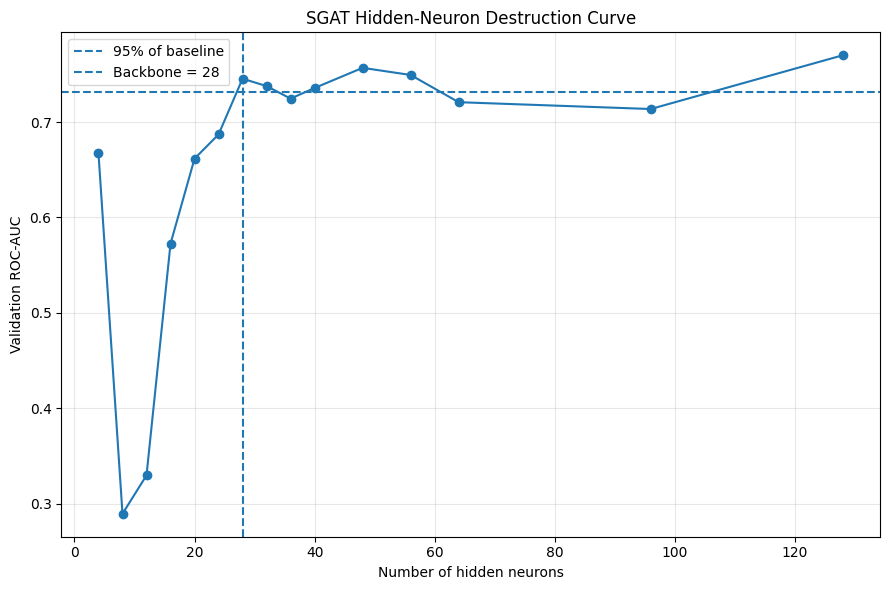

Saved:
/content/drive/My Drive/GNN Project/sgat_neuron_destruction_roc_auc.png


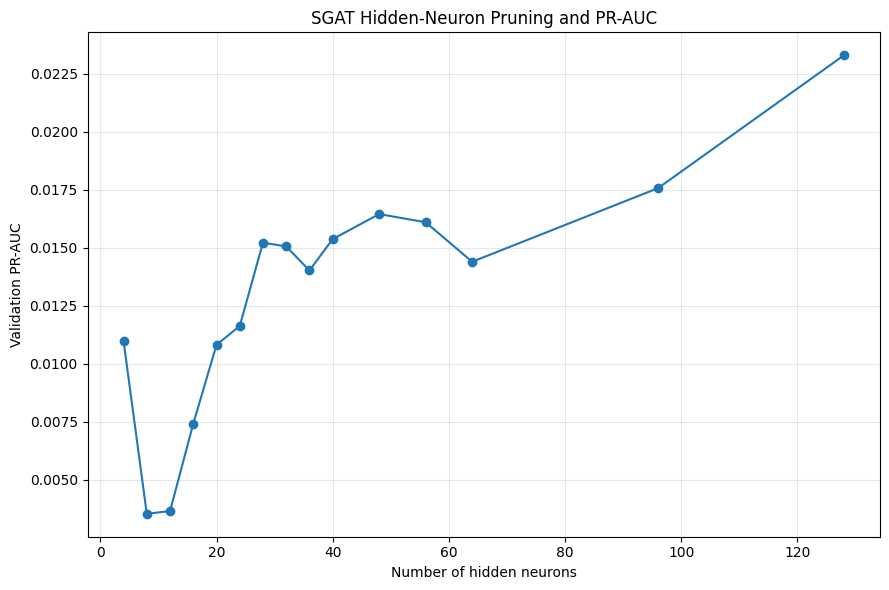

Saved:
/content/drive/My Drive/GNN Project/sgat_neuron_pruning_pr_auc.png

FINAL EXPERIMENT PACKAGE COMPLETE
Summary:
/content/drive/My Drive/GNN Project/final_experiment_summary.json

Metrics:
/content/drive/My Drive/GNN Project/final_model_comparison.csv

Destruction data:
/content/drive/My Drive/GNN Project/sgat_destruction_curve.csv

Figures:
/content/drive/My Drive/GNN Project/sgat_neuron_destruction_roc_auc.png
/content/drive/My Drive/GNN Project/sgat_neuron_pruning_pr_auc.png


In [ ]:
# ============================================================
# STEP 10 — FINAL EXPERIMENT PACKAGE
# ============================================================

import os
import json
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt

PROJECT_DIR = "/content/drive/My Drive/GNN Project"


# ============================================================
# 1. FINAL METRICS TABLE
# ============================================================

final_metrics = pd.DataFrame([
    {
        "Model": "GAT baseline",
        "Hidden neurons": 128,
        "ROC-AUC": 0.6860,
        "ROC-AUC std": 0.0601,
        "PR-AUC": 0.0093,
        "PR-AUC std": 0.0020,
        "Edge sparsity": 0.0
    },
    {
        "Model": "SGAT",
        "Hidden neurons": 128,
        "ROC-AUC": original_test_roc,
        "ROC-AUC std": np.nan,
        "PR-AUC": original_test_pr,
        "PR-AUC std": np.nan,
        "Edge sparsity": checkpoint["sparsity"]
    },
    {
        "Model": "SGAT backbone",
        "Hidden neurons": backbone,
        "ROC-AUC": final_test_roc,
        "ROC-AUC std": np.nan,
        "PR-AUC": final_test_pr,
        "PR-AUC std": np.nan,
        "Edge sparsity": checkpoint["sparsity"]
    }
])

print("=" * 80)
print("FINAL MODEL COMPARISON")
print("=" * 80)

display(final_metrics)


# ============================================================
# 2. SAVE METRICS TABLE
# ============================================================

metrics_path = os.path.join(
    PROJECT_DIR,
    "final_model_comparison.csv"
)

final_metrics.to_csv(
    metrics_path,
    index=False
)

print("\nSaved:")
print(metrics_path)


# ============================================================
# 3. SAVE DESTRUCTION CURVE DATA
# ============================================================

destruction_path = os.path.join(
    PROJECT_DIR,
    "sgat_destruction_curve.csv"
)

df_pruning.to_csv(
    destruction_path,
    index=False
)

print("Saved:")
print(destruction_path)


# ============================================================
# 4. SAVE ROC-AUC DESTRUCTION CURVE
# ============================================================

plot_df = df_pruning.sort_values(
    "neurons"
)

plt.figure(figsize=(9, 6))

plt.plot(
    plot_df["neurons"],
    plot_df["val_roc_auc"],
    marker="o"
)

plt.axhline(
    threshold_95,
    linestyle="--",
    label="95% of baseline"
)

plt.axvline(
    backbone,
    linestyle="--",
    label=f"Backbone = {backbone}"
)

plt.xlabel(
    "Number of hidden neurons"
)

plt.ylabel(
    "Validation ROC-AUC"
)

plt.title(
    "SGAT Hidden-Neuron Destruction Curve"
)

plt.legend()

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

roc_curve_path = os.path.join(
    PROJECT_DIR,
    "sgat_neuron_destruction_roc_auc.png"
)

plt.savefig(
    roc_curve_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(roc_curve_path)


# ============================================================
# 5. SAVE PR-AUC CURVE
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    plot_df["neurons"],
    plot_df["val_pr_auc"],
    marker="o"
)

plt.xlabel(
    "Number of hidden neurons"
)

plt.ylabel(
    "Validation PR-AUC"
)

plt.title(
    "SGAT Hidden-Neuron Pruning and PR-AUC"
)

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

pr_curve_path = os.path.join(
    PROJECT_DIR,
    "sgat_neuron_pruning_pr_auc.png"
)

plt.savefig(
    pr_curve_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(pr_curve_path)


# ============================================================
# 6. FINAL EXPERIMENT SUMMARY
# ============================================================

summary = {
    "dataset": {
        "nodes": 15882,
        "edge_entries": 473424,
        "features": 3,
        "positive_nodes": 74,
        "negative_nodes": 15808,
        "positive_prevalence": 74 / 15882
    },

    "baseline_gat": {
        "test_roc_auc_mean": 0.6860,
        "test_roc_auc_std": 0.0601,
        "test_pr_auc_mean": 0.0093,
        "test_pr_auc_std": 0.0020,
        "seeds": [42, 123, 456, 789, 2024]
    },

    "sgat": {
        "hidden_neurons": 128,
        "test_roc_auc": float(original_test_roc),
        "test_pr_auc": float(original_test_pr),
        "edge_sparsity": float(checkpoint["sparsity"]),
        "original_edge_entries": int(checkpoint["total_edge_entries"]),
        "retained_edge_entries": int(checkpoint["retained_edge_entries"]),
        "removed_edge_entries": int(checkpoint["removed_edge_entries"])
    },

    "backbone": {
        "neurons": int(backbone),
        "validation_roc_auc": float(
            backbone_result["val_roc_auc"]
        ),
        "validation_pr_auc": float(
            backbone_result["val_pr_auc"]
        ),
        "test_roc_auc": float(final_test_roc),
        "test_pr_auc": float(final_test_pr),
        "neuron_reduction_percent": float(
            (1 - backbone / 128) * 100
        ),
        "selection_threshold": 0.95,
        "validation_threshold": float(threshold_95)
    }
}

summary_path = os.path.join(
    PROJECT_DIR,
    "final_experiment_summary.json"
)

with open(
    summary_path,
    "w"
) as f:
    json.dump(
        summary,
        f,
        indent=4
    )

print("\n" + "=" * 80)
print("FINAL EXPERIMENT PACKAGE COMPLETE")
print("=" * 80)

print("Summary:")
print(summary_path)

print("\nMetrics:")
print(metrics_path)

print("\nDestruction data:")
print(destruction_path)

print("\nFigures:")
print(roc_curve_path)
print(pr_curve_path)

In [ ]:
# ============================================================
# RESTORE GENE/PROTEIN MAPPINGS
# ============================================================

all_proteins = data_dict["all_proteins"]
protein_to_idx = data_dict["protein_to_idx"]
protein_to_gene = data_dict["protein_to_gene"]

print("=" * 70)
print("MAPPINGS RESTORED")
print("=" * 70)

print("All proteins      :", len(all_proteins))
print("Protein → index   :", len(protein_to_idx))
print("Protein → gene    :", len(protein_to_gene))

MAPPINGS RESTORED
All proteins      : 15882
Protein → index   : 15882
Protein → gene    : 19699


In [ ]:
# ============================================================
# STEP 11 — FINAL DISEASE-GENE RANKING
# ============================================================

import pandas as pd
import numpy as np
import torch
import os


# ============================================================
# 1. RUN FINAL 28-NEURON BACKBONE
# ============================================================

final_pruned_model.eval()

with torch.no_grad():

    output = final_pruned_model(
        data.x,
        data.edge_index
    )

    # SGAT output:
    # output[0] = node logits
    # output[1] = edge gates

    logits = output[0]

    probabilities = torch.sigmoid(
        logits
    ).cpu().numpy()


# ============================================================
# 2. CREATE NODE → PROTEIN MAPPING
# ============================================================

# protein_to_idx:
#     protein ID → node index

idx_to_protein = {
    idx: protein
    for protein, idx in protein_to_idx.items()
}


# ============================================================
# 3. CREATE NODE → GENE MAPPING
# ============================================================

node_to_gene = {}

for idx in range(data.num_nodes):

    protein = idx_to_protein.get(idx)

    if protein is None:
        node_to_gene[idx] = None
        continue

    gene = protein_to_gene.get(protein)

    node_to_gene[idx] = gene


# ============================================================
# 4. BUILD COMPLETE RANKING
# ============================================================

ranking_rows = []

for idx in range(data.num_nodes):

    protein = idx_to_protein.get(idx)

    gene = node_to_gene.get(idx)

    score = probabilities[idx]

    label = int(data.y[idx].item())

    ranking_rows.append({
        "rank": 0,
        "node_index": idx,
        "protein_id": protein,
        "gene": gene,
        "prediction_score": float(score),
        "known_disease_gene": label
    })


ranking_df = pd.DataFrame(
    ranking_rows
)


# Sort highest predicted probability first
ranking_df = ranking_df.sort_values(
    "prediction_score",
    ascending=False
).reset_index(drop=True)


# Assign rank
ranking_df["rank"] = (
    np.arange(len(ranking_df)) + 1
)


# ============================================================
# 5. DISPLAY TOP 30 CANDIDATES
# ============================================================

print("=" * 100)
print("TOP 30 PREDICTED DISEASE-GENE CANDIDATES")
print("=" * 100)

display(
    ranking_df[
        [
            "rank",
            "gene",
            "protein_id",
            "prediction_score",
            "known_disease_gene"
        ]
    ].head(30)
)


# ============================================================
# 6. RANK KNOWN DISEASE GENES
# ============================================================

known_genes_df = ranking_df[
    ranking_df["known_disease_gene"] == 1
].copy()


known_genes_df = known_genes_df.sort_values(
    "prediction_score",
    ascending=False
).reset_index(drop=True)


known_genes_df["disease_gene_rank"] = (
    np.arange(len(known_genes_df)) + 1
)


print()
print("=" * 100)
print("KNOWN DIABETES MELLITUS GENES — RANKED BY MODEL SCORE")
print("=" * 100)

display(
    known_genes_df[
        [
            "disease_gene_rank",
            "gene",
            "protein_id",
            "prediction_score",
            "rank"
        ]
    ]
)


# ============================================================
# 7. SAVE COMPLETE CANDIDATE RANKING
# ============================================================

ranking_path = os.path.join(
    PROJECT_DIR,
    "sgat_disease_gene_ranking.csv"
)

ranking_df.to_csv(
    ranking_path,
    index=False
)


# ============================================================
# 8. SAVE KNOWN DISEASE-GENE RANKING
# ============================================================

known_ranking_path = os.path.join(
    PROJECT_DIR,
    "sgat_known_disease_gene_ranking.csv"
)

known_genes_df.to_csv(
    known_ranking_path,
    index=False
)


print()
print("=" * 100)
print("GENE RANKINGS SAVED")
print("=" * 100)

print(
    "Complete candidate ranking:"
)
print(ranking_path)

print()

print(
    "Known disease-gene ranking:"
)
print(known_ranking_path)

TOP 30 PREDICTED DISEASE-GENE CANDIDATES


,rank,gene,protein_id,prediction_score,known_disease_gene
0,1,EGFR,ENSP00000275493,0.515776,0
1,2,CTNNB1,ENSP00000495360,0.515350,0
2,3,TP53,ENSP00000269305,0.514137,0
3,4,SRC,ENSP00000362680,0.512597,0
4,5,TRIM28,ENSP00000253024,0.512108,0
5,6,DLG4,ENSP00000497806,0.510035,0
6,7,RHOA,ENSP00000400175,0.509821,0
7,8,MYC,ENSP00000478887,0.506606,0
8,9,RANBP1,ENSP00000401564,0.506470,0
9,10,ZNF816,ENSP00000350295,0.506035,0



KNOWN DIABETES MELLITUS GENES — RANKED BY MODEL SCORE


,disease_gene_rank,gene,protein_id,prediction_score,rank
0,1,FN1,ENSP00000346839,0.505371,13
1,2,RAC1,ENSP00000348461,0.505182,15
2,3,INS,ENSP00000380432,0.504065,26
3,4,CAV1,ENSP00000339191,0.503989,27
4,5,GNAS,ENSP00000360141,0.503842,30
...,...,...,...,...,...
69,70,HLA-DQB1,ENSP00000364080,0.495005,12221
70,71,POLD1,ENSP00000472445,0.494705,12834
71,72,ATM,ENSP00000278616,0.494201,13594
72,73,SARS2,ENSP00000472847,0.493497,14323



GENE RANKINGS SAVED
Complete candidate ranking:
/content/drive/My Drive/GNN Project/sgat_disease_gene_ranking.csv

Known disease-gene ranking:
/content/drive/My Drive/GNN Project/sgat_known_disease_gene_ranking.csv


In [ ]:
# ============================================================
# FINAL EXPERIMENT REPORT
# ============================================================

import os
import json
from datetime import datetime

PROJECT_DIR = "/content/drive/My Drive/GNN Project"

final_report = {
    "project": "GNN-Based Drug Target Identification",

    "dataset": {
        "nodes": 15882,
        "edge_entries": 473424,
        "features": 3,
        "positive_genes": 74,
        "negative_nodes": 15808,
        "positive_prevalence": 74 / 15882,
        "ppi_source": "STRING",
        "disease_association_source": "DisGeNET",
        "disease": "Diabetes Mellitus"
    },

    "baseline_gat": {
        "seeds": [42, 123, 456, 789, 2024],
        "test_roc_auc_mean": 0.6860,
        "test_roc_auc_std": 0.0601,
        "test_pr_auc_mean": 0.0093,
        "test_pr_auc_std": 0.0020,
        "hidden_channels": 128,
        "heads": 4,
        "dropout": 0.2,
        "learning_rate": 0.0001,
        "weight_decay": 0.0005
    },

    "sgat": {
        "hidden_channels": 128,
        "test_roc_auc": 0.6817415138,
        "test_pr_auc": 0.0167395082,
        "edge_entries_original": 473424,
        "edge_entries_retained": 135008,
        "edge_entries_removed": 338416,
        "edge_sparsity": 0.7148264558,
        "best_validation_roc_auc": 0.7699884003
    },

    "neuron_pruning": {
        "original_neurons": 128,
        "backbone_neurons": 28,
        "neuron_reduction": 0.78125,
        "selection_rule":
            "Smallest tested representation retaining at least 95% of unpruned validation ROC-AUC",
        "baseline_validation_roc_auc": 0.7699884003,
        "threshold_95_percent": 0.7314899803,
        "backbone_validation_roc_auc": 0.745418,
        "backbone_validation_pr_auc": 0.015222
    },

    "final_backbone": {
        "neurons": 28,
        "test_roc_auc": 0.713978,
        "test_pr_auc": 0.014156,
        "edge_sparsity": 0.7148264558
    },

    "files": {
        "model": "diabetes_sgat_best.pt",
        "sgat_results": "diabetes_sgat_results.json",
        "model_comparison": "final_model_comparison.csv",
        "destruction_curve": "sgat_destruction_curve.csv",
        "gene_ranking": "sgat_disease_gene_ranking.csv",
        "known_gene_ranking": "sgat_known_disease_gene_ranking.csv",
        "roc_curve": "sgat_neuron_destruction_roc_auc.png",
        "pr_curve": "sgat_neuron_pruning_pr_auc.png"
    }
}

report_path = os.path.join(
    PROJECT_DIR,
    "FINAL_EXPERIMENT_REPORT.json"
)

with open(report_path, "w") as f:
    json.dump(
        final_report,
        f,
        indent=4
    )

print("=" * 80)
print("FINAL EXPERIMENT REPORT SAVED")
print("=" * 80)
print(report_path)

FINAL EXPERIMENT REPORT SAVED
/content/drive/My Drive/GNN Project/FINAL_EXPERIMENT_REPORT.json
